# TF-Gene Regulatory Network Analysis with NetworkX
### A hands-on introduction to graph theory for GRNs

This notebook walks through the core graph theory concepts you need to interpret a
gene regulatory network (GRN) built from ChIP-seq TF-target data.

Each section has:
- A short explanation of the concept and why it matters biologically
- A code cell with **blanks for you to fill in** (marked `# TODO`)
- A collapsible **hint** if you get stuck
- A collapsible **solution** to check your work

Work through them in order — later sections build on earlier ones.


In [1]:
import networkx as nx
import matplotlib.pyplot as plt


## 1. Building the Graph

A gene regulatory network is naturally a **directed graph**: an edge from `TF1 -> GeneA`
means TF1 regulates GeneA, and that relationship doesn't go the other way (usually).

Below is a toy edge list of (TF, target_gene) pairs derived from ChIP-seq peaks
(imagine these came from mapping peaks to nearest genes).

**Your task:** create a directed graph `G` from the edge list.


In [3]:
edges = [
    ("TF1", "GeneA"),
    ("TF1", "GeneB"),
    ("TF1", "GeneC"),
    ("TF2", "GeneB"),
    ("TF2", "GeneD"),
    ("TF2", "TF3"),
    ("TF3", "GeneD"),
    ("TF3", "GeneE"),
    ("GeneD", "TF1"),
]

# TODO: create a directed graph object and add the edges above
G = nx.DiGraph()
G.add_edges_from(edges)

# TODO: print the number of nodes and edges
print(f"Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")

print(G)

Nodes: 8, Edges: 9
DiGraph with 8 nodes and 9 edges


<details>
<summary>💡 Hint (click to expand)</summary>

NetworkX has a dedicated class for directed graphs. Look for `nx.DiGraph()`.
Once you have an empty graph object, there's an `.add_edges_from()` method that takes a list of tuples directly.

</details>

<details>
<summary>✅ Solution (click to expand)</summary>

```python
G = nx.DiGraph()
G.add_edges_from(edges)

print(f"Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")
```

</details>

**Why directed?** Undirected graphs would treat `TF1 -> GeneA` the same as `GeneA -> TF1`,
which would erase the biological meaning of "who regulates whom." Always use `DiGraph`
(or `MultiDiGraph` if the same TF-target pair can have multiple ChIP-seq peaks/edges) for GRNs.


## 2. Degree — Finding Hub Regulators

- **Out-degree**: how many genes a node regulates → high out-degree TFs are "master regulators"
- **In-degree**: how many TFs regulate a node → high in-degree genes are heavily co-regulated

**Your task:** compute out-degree and in-degree for every node, then print the top 3
TFs by out-degree.


In [4]:
# TODO: get a dictionary of out-degrees for all nodes
out_degrees = dict(G.out_degree())

# TODO: get a dictionary of in-degrees for all nodes
in_degrees = dict(G.in_degree())

# TODO: print the top 3 nodes by out-degree, sorted highest first
sorted_out_degrees = sorted(out_degrees.items(), key=lambda x: x[1], reverse=True)

# ALTERNATIVELY
# The lambda function is the same as defining this and then calling it: key=get_degree
def get_degree(item):
    #node_name = item[0]
    #degree_value = item[1]
    return item[1]


for node, deg in sorted_out_degrees[0:3]:
    print(f"Node {node} regulates {deg} genes.")


Node TF1 regulates 3 genes.
Node TF2 regulates 3 genes.
Node TF3 regulates 2 genes.


<details>
<summary>✅ Solution (click to expand)</summary>

```python
out_degrees = dict(G.out_degree())
in_degrees = dict(G.in_degree())

print("Top 3 TFs by out-degree:")
for node, deg in sorted(out_degrees.items(), key=lambda x: -x[1])[:3]:
    print(f"  {node}: regulates {deg} genes")
```

</details>

**Biological interpretation:** if you sorted your real ChIP-seq network by out-degree
and saw one TF regulating hundreds of genes while most regulate a handful, that's consistent
with the **scale-free** structure typical of biological networks — a few hub regulators,
many peripheral ones.


## 3. Centrality — Who's Structurally Important (Beyond Just Degree)?

Degree only counts *direct* connections. Centrality measures capture more subtle importance:

- **Betweenness centrality**: how often a node lies on the shortest path between other nodes
  (bottlenecks/bridges between regulatory modules)
- **PageRank**: importance based on being pointed to by *other important* nodes
  (works well for directed graphs — same algorithm Google used for web pages)

**Your task:** compute both and print the top 3 nodes for each.


In [5]:
# TODO: compute betweenness centrality (hint: there's an nx function for this)
betweenness = nx.betweenness_centrality(G)

# TODO: compute PageRank
pagerank = nx.pagerank(G)

# TODO: print top 3 nodes by betweenness centrality (with scores)
top_centrality = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)
for pair in top_centrality[0:3]:
    print(f'Node {pair[0]} with score {pair[1]:.3f}')

# Alternatively
#for node, score in top_centrality[0:3]:
#    print(f'Node {node}: score {score}')

# TODO: print top 3 nodes by PageRank (with scores)
top_pagerank = sorted(pagerank.items(), key=lambda x: x[1], reverse=True)
for node, score in top_pagerank[:3]:
    print(f'Node {node} has pagerank {score:.3f}')


Node TF1 with score 0.190
Node GeneD with score 0.167
Node TF3 with score 0.024
Node TF1 has pagerank 0.187
Node GeneB has pagerank 0.147
Node GeneD has pagerank 0.134


<details>
<summary>💡 Hint (click to expand)</summary>

Look for `nx.betweenness_centrality(G)` and `nx.pagerank(G)`. Both return
dictionaries mapping node -> score, same sorting trick as before applies.

</details>

<details>
<summary>✅ Solution (click to expand)</summary>

```python
betweenness = nx.betweenness_centrality(G)
pagerank = nx.pagerank(G)

print("Top 3 by betweenness centrality:")
for node, score in sorted(betweenness.items(), key=lambda x: -x[1])[:3]:
    print(f"  {node}: {score:.3f}")

print("Top 3 by PageRank:")
for node, score in sorted(pagerank.items(), key=lambda x: -x[1])[:3]:
    print(f"  {node}: {score:.3f}")
```

</details>

**Think about it:** could a node have low out-degree but high betweenness centrality?
What would that mean biologically? (Hint: imagine a TF that connects two otherwise
separate regulatory modules, even if it only has 1-2 direct targets.)


### **<span style="color: red">==========================================================================</span>**
### **Notes**
1. G is a diGraph: implemented as nested dictionaries, but don't worry about that, just use its methods. edges is a list of tuples
2. G.out_degree() is a DiDegreeView object. Wrapping it in dict() will make it a regular dictionary like {"string": int, ...}
3. nx.betweenness_centrality(G) and nx.pagerank(G) are both dicts {"string": float, ...}
4. nx.weakly_connected_components(G) returns a generator. 
just wrap it in a list() to make it a list of sets: [{"TF1", "GeneA", "GeneB"}, {"TF3", "GeneE"}]
5. G.successors(a) returns an iterator

- Several functions return 'lazy objects' like views or generators (these should be converted to dicts and lists)


### **Recall basic types**

List: ordered, mutable, duplicates, not hashable
- nodes = ["TF1", "TF2", "TF1"]
- you can get len(), sorted() to get new list, .append(), nodes[0], check membership: `"TF1" in nodes` (true or false)

Tuple: ordered, immutable, duplicates, hashable
- edge = ("TF1", "GeneA")
- can get len(), edge[0], a, b = edge

Set: unordered, mutable, no duplicates
- component = {"TF1", "GeneA", "GeneB"}
- .add(), membership check, can do intersection (&) union (|) and difference (-)

Dictionary: unordered, mutable, no duplicate keys
- out_degrees = {"TF1": 3, "TF2": 2}
- can access by key or value, can get views using .keys(), .values(), .items() (tuples)

**Lazy objects**: fetch values when needed. Do not actually store values
Views: points to a dictionary (live) like dict.items() or G.out_degree()
- can loop over items: for k, v in d.items():
- Can wrap into a list or dict to get a snapshot

Generator: 
- gen = nx.weakly_connected_components(G)
- Produces items one at a time, on demand, as you iterate — doesn't compute everything upfront
- Can only be consumed once — after you loop through it fully (or convert to a list), it's exhausted; looping again gives nothing
- Can't index (gen[0]) or check len() until converted

### **<span style="color: red">---------------------------------------------------------------------------</span>**

## 4. Connected Components — Is This One Network or Several?

- **Weakly connected components**: ignore edge direction — are nodes reachable from each other at all?
- **Strongly connected components**: respect edge direction — can you get from A to B *and back*?
  A strongly connected component with more than 1 node means there's a **feedback loop**.

**Your task:** find both types of components.


In [6]:
# TODO: get the list of weakly connected components
weak_components = list(nx.weakly_connected_components(G))

# TODO: get the list of strongly connected components with more than 1 node
# (these indicate feedback loops)
strong_components = []
for c in nx.strongly_connected_components(G):
    if len(c) > 1: 
        strong_components.append(c)


print(f"Weakly connected components: {len(weak_components)}")
print(f"Strongly connected components (feedback loops): {strong_components}")
# There are none of these


Weakly connected components: 1
Strongly connected components (feedback loops): []


<details>
<summary>💡 Hint (click to expand)</summary>

`nx.weakly_connected_components(G)` and `nx.strongly_connected_components(G)` both
return generators of sets — wrap in `list()`. For the strongly-connected one, you'll need
a list comprehension with a condition on `len(c) > 1` to filter out trivial single-node components.

</details>

<details>
<summary>✅ Solution (click to expand)</summary>

```python
weak_components = list(nx.weakly_connected_components(G))
strong_components = [c for c in nx.strongly_connected_components(G) if len(c) > 1]

print(f"Weakly connected components: {len(weak_components)}")
print(f"Strongly connected components (feedback loops): {strong_components}")
```

</details>

**Why this matters:** if your real ChIP-seq network has many small weakly-connected
components instead of one big one, that could mean your peak-to-gene mapping is too strict,
your TF panel doesn't cover enough of the network, or the biology genuinely involves separate
regulatory modules. Worth investigating before drawing conclusions from centrality scores.


## 5. Motif Detection — Feed-Forward Loops

The **feed-forward loop** (FFL) is the most-studied network motif in gene regulation
(see Uri Alon's work). It looks like:

```
TF_A -> TF_B
TF_A -> Gene_C
TF_B -> Gene_C
```

TF_A regulates Gene_C both directly and indirectly (through TF_B). This wiring pattern
shows up far more often than chance in real GRNs and has specific dynamical properties
(e.g., filtering out transient signals).

**Your task:** write a function that finds all feed-forward loops in `G`.


In [7]:
def find_feed_forward_loops(G):
    ffls = []
    # TODO: for every node 'a', look at its successors 'b'
    #       for every successor 'b' of 'a', look at its successors 'c'
    #       if 'a' also has a direct edge to 'c', that's a feed-forward loop!
    for a in G.nodes():
        for b in G.successors(a):
            for c in G.successors(b):
                if G.has_edge(a,c)==True: ffls.append((a,b,c))
    return ffls

ffls = find_feed_forward_loops(G)
print(f"Feed-forward loops found: {len(ffls)}")
for a, b, c in ffls:
    print(f"  {a} -> {b} -> {c}, and {a} -> {c} directly")


Feed-forward loops found: 1
  TF2 -> TF3 -> GeneD, and TF2 -> GeneD directly


<details>
<summary>💡 Hint (click to expand)</summary>

You'll need nested loops: `for a in G.nodes()`, then `for b in G.successors(a)`,
then `for c in G.successors(b)`. Inside the innermost loop, check `G.has_edge(a, c)` —
if true, append `(a, b, c)` to the list.

</details>

<details>
<summary>✅ Solution (click to expand)</summary>

```python
def find_feed_forward_loops(G):
    ffls = []
    for a in G.nodes():
        for b in G.successors(a):
            for c in G.successors(b):
                if G.has_edge(a, c):
                    ffls.append((a, b, c))
    return ffls

ffls = find_feed_forward_loops(G)
print(f"Feed-forward loops found: {len(ffls)}")
for a, b, c in ffls:
    print(f"  {a} -> {b} -> {c}, and {a} -> {c} directly")
```

</details>

## 6. Visualize the Network

Finally, draw the network with node size scaled by out-degree, so hub regulators
visually pop out.

**Your task:** build a layout, scale node sizes by out-degree, and draw it.


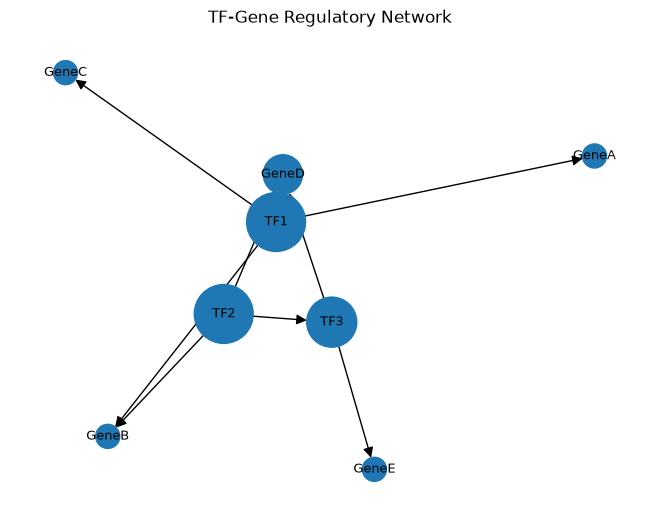

In [10]:
# TODO: create a layout for the nodes (try nx.spring_layout)
pos = nx.spring_layout(G, seed=42)

# TODO: scale node sizes using out_degrees (e.g. base size + multiplier * degree)
node_sizes = [300 + 500 * out_degrees.get(n,0) for n in G.nodes()]

# TODO: draw the graph with nx.draw(), passing pos, node_sizes, with_labels=True, arrows=True
#nx.draw(G, pos, node_size=node_sizes, with_labels=True, arrows=True)

nx.draw(
    G, pos, with_labels=True, node_size=node_sizes,
    #node_color="lightblue", edge_color="gray",
    arrows=True, arrowsize=15, font_size=9
)
plt.title("TF-Gene Regulatory Network")
plt.show()


<details>
<summary>💡 Hint (click to expand)</summary>

`nx.spring_layout(G, seed=42)` gives reproducible positions. For sizes, a list
comprehension works: `[300 + 500 * out_degrees.get(n, 0) for n in G.nodes()]`.
Then `nx.draw(G, pos, node_size=node_sizes, with_labels=True, arrows=True)`.

</details>

<details>
<summary>✅ Solution (click to expand)</summary>

```python
pos = nx.spring_layout(G, seed=42)
node_sizes = [300 + 500 * out_degrees.get(n, 0) for n in G.nodes()]

nx.draw(
    G, pos, with_labels=True, node_size=node_sizes,
    node_color="lightblue", edge_color="gray",
    arrows=True, arrowsize=15, font_size=9
)
plt.title("TF-Gene Regulatory Network")
plt.show()
```

</details>

## 7. Next Steps: Using Your Real Data

Once you're past peak calling, replace the toy `edges` list at the top with your real
TF-target pairs. If you have a CSV with columns like `TF, target_gene`:

```python
import pandas as pd
df = pd.read_csv("tf_target_edges.csv")
G = nx.from_pandas_edgelist(df, source="TF", target="target", create_using=nx.DiGraph())
```

Then re-run every cell above unchanged — all the analysis applies directly to your real network.

### Questions to explore on your own data
- Does the degree distribution look scale-free (few hubs, many low-degree nodes)?
- Do the highest-betweenness nodes match known "bottleneck" regulators in the literature?
- How many feed-forward loops do you find, and do they involve known co-regulatory pairs?
- Is the network one connected component, or fragmented? What might explain that?


In [ ]:
# Unused code for actual graph building (7/28)
import pandas as pd
import networkx as nx

# From CSV file
df = pd.read_csv("../results/macs3/tf_target_edges.csv")  # columns: TF, target
df = pd.read_csv("../results/macs3/tf_target_edges.csv")
G = nx.from_pandas_edgelist(
    df, source="TF", target="target_gene",
    edge_attr=["peak_score", "distance_to_tss"],
    create_using=nx.DiGraph()
)
